# Distance based localization – a minimal example

This notebook shows, step by step, how to set up **distance based localization**
with the ERT Python API and how it differs from a **global** (non-localized) update.

The setup is intentionally tiny and runs in a few seconds:

* A 40 × 40 grid with 100 m cells and one `FIELD` parameter, `PORO`.
* Three wells, each with one `SUMMARY_OBSERVATION` that has a `LOCALIZATION` block
  (`EAST`, `NORTH`, `RADIUS`).
* Instead of running a simulator, we generate the prior ensemble and the simulated
  responses directly in Python and save them to ERT storage.
* We then run the ensemble smoother update twice: once with `GLOBAL` and once with
  `DISTANCE` as the update strategy for `FIELD` parameters.

The only difference between the two runs is a single line in the ERT config:

```
ANALYSIS_SET_VAR PARAMETERS FIELD GLOBAL     # or DISTANCE
```

In [1]:
import tempfile
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import xarray as xr
import xtgeo

from ert.analysis import build_strategy_map, smoother_update
from ert.config import ErtConfig
from ert.storage import open_storage

warnings.filterwarnings("ignore", message="Config contains a SUMMARY key")

## 1. Problem setup

Each well observes the average `PORO` value in the 3 × 3 cells around it.
In the prior, `PORO` is independent standard normal noise in every cell, so the
*true* correlation between a well response and any cell outside its 3 × 3
neighbourhood is zero. With only 50 realizations, however, the *sample*
correlations are not zero – these are the spurious correlations that
localization is designed to suppress.

In [2]:
NX, NY, CELL_SIZE = 40, 40, 100.0
ENSEMBLE_SIZE = 50
OBSERVATION_DATE = "2020-01-01"
RADIUS = 400.0

# well name: (east, north, observed value)
WELLS = {
    "OP1": (1050.0, 1050.0, 0.6),
    "OP2": (2950.0, 1550.0, -0.6),
    "OP3": (1550.0, 3050.0, 0.5),
}

workdir = Path(tempfile.mkdtemp())
print(f"Working directory: {workdir}")

Working directory: /tmp/tmp3k4gukka


## 2. Grid and observations

`FIELD` parameters need a grid. We create a simple box grid with `xtgeo`.

Every observation gets a `LOCALIZATION` block. This is what distance based
localization uses to decide which grid cells each observation may update.
The influence is full (1.0) at the well and decays smoothly
(Gaspari-Cohn) to zero at a distance of `2 × RADIUS`.

In [3]:
xtgeo.create_box_grid((NX, NY, 1), increment=(CELL_SIZE, CELL_SIZE, 10.0)).to_file(
    workdir / "GRID.EGRID", fformat="egrid"
)

observations = ""
for well, (east, north, value) in WELLS.items():
    observations += f"""
SUMMARY_OBSERVATION WOPR_{well}
{{
    KEY   = WOPR:{well};
    VALUE = {value};
    ERROR = 0.1;
    DATE  = {OBSERVATION_DATE};
    LOCALIZATION {{
        EAST   = {east};
        NORTH  = {north};
        RADIUS = {RADIUS};
    }};
}};
"""
(workdir / "observations.txt").write_text(observations)
print(observations)


SUMMARY_OBSERVATION WOPR_OP1
{
    KEY   = WOPR:OP1;
    VALUE = 0.6;
    ERROR = 0.1;
    DATE  = 2020-01-01;
    LOCALIZATION {
        EAST   = 1050.0;
        NORTH  = 1050.0;
        RADIUS = 400.0;
    };
};

SUMMARY_OBSERVATION WOPR_OP2
{
    KEY   = WOPR:OP2;
    VALUE = -0.6;
    ERROR = 0.1;
    DATE  = 2020-01-01;
    LOCALIZATION {
        EAST   = 2950.0;
        NORTH  = 1550.0;
        RADIUS = 400.0;
    };
};

SUMMARY_OBSERVATION WOPR_OP3
{
    KEY   = WOPR:OP3;
    VALUE = 0.5;
    ERROR = 0.1;
    DATE  = 2020-01-01;
    LOCALIZATION {
        EAST   = 1550.0;
        NORTH  = 3050.0;
        RADIUS = 400.0;
    };
};



## 3. ERT configuration

The config is the same for both runs except for the update strategy of
`FIELD` parameters.

In [4]:
def ert_config(strategy: str) -> ErtConfig:
    config_file = workdir / f"{strategy.lower()}.ert"
    config_file.write_text(
        f"""
NUM_REALIZATIONS {ENSEMBLE_SIZE}
GRID GRID.EGRID
FIELD PORO PARAMETER poro.roff INIT_FILES:poro_%d.roff

ECLBASE CASE
SUMMARY WOPR:*
OBS_CONFIG observations.txt

ANALYSIS_SET_VAR PARAMETERS FIELD {strategy}
"""
    )
    return ErtConfig.from_file(config_file)


print(ert_config("DISTANCE").ensemble_config.parameter_configs["PORO"].update_strategy)

distance


## 4. Prior ensemble and simulated responses

Normally ERT samples the prior and runs a forward model to produce the summary
responses. Here we create both directly so the example is self-contained.
The same prior is used for both runs.

In [5]:
rng = np.random.default_rng(42)
prior_poro = rng.standard_normal((ENSEMBLE_SIZE, NX, NY, 1)).astype(np.float32)


def simulate_wopr(poro: np.ndarray, east: float, north: float) -> float:
    i, j = int(east // CELL_SIZE), int(north // CELL_SIZE)
    return float(poro[i - 1 : i + 2, j - 1 : j + 2, 0].mean())


def save_prior(ensemble) -> None:
    for realization in range(ENSEMBLE_SIZE):
        poro = prior_poro[realization]
        ensemble.save_parameters(
            xr.DataArray(poro, name="values", dims=["x", "y", "z"]).to_dataset(),
            "PORO",
            realization,
        )
        ensemble.save_response(
            "summary",
            pl.DataFrame(
                {
                    "response_key": [f"WOPR:{well}" for well in WELLS],
                    "time": pl.Series(
                        [datetime.fromisoformat(OBSERVATION_DATE)] * len(WELLS)
                    ).dt.cast_time_unit("ms"),
                    "values": pl.Series(
                        [simulate_wopr(poro, e, n) for e, n, _ in WELLS.values()],
                        dtype=pl.Float32,
                    ),
                }
            ),
            realization,
        )

## 5. Run the update

For each strategy we:

1. create an experiment from the ERT config,
2. store the prior ensemble,
3. build the strategy map (this is where `GLOBAL` / `DISTANCE` is picked up
   from the parameter config), and
4. call `smoother_update` to produce the posterior.

In [6]:
def run_update(storage, strategy: str) -> tuple[np.ndarray, np.ndarray]:
    config = ert_config(strategy)
    experiment = storage.create_experiment(
        experiment_config={
            "parameter_configuration": [
                p.model_dump(mode="json")
                for p in config.ensemble_config.parameter_configuration
            ],
            "response_configuration": [
                r.model_dump(mode="json")
                for r in config.ensemble_config.response_configuration
            ],
            "observations": [
                o.model_dump(mode="json") for o in config.observation_declarations
            ],
            "shape_registry": config.shape_registry.model_dump(mode="json"),
        },
        name=strategy,
    )
    prior = storage.create_ensemble(
        experiment, ensemble_size=ENSEMBLE_SIZE, name="prior"
    )
    save_prior(prior)
    posterior = storage.create_ensemble(
        experiment,
        ensemble_size=ENSEMBLE_SIZE,
        iteration=1,
        name="posterior",
        prior_ensemble=prior,
    )

    es_settings = config.analysis_config.es_settings
    strategy_map = build_strategy_map(
        parameters=experiment.update_parameters,
        param_configs=experiment.parameter_configuration,
        enkf_truncation=es_settings.enkf_truncation,
        correlation_threshold=es_settings.correlation_threshold,
        experiment=experiment,
    )
    smoother_update(
        prior,
        posterior,
        observations=experiment.observation_keys,
        update_settings=config.analysis_config.observation_settings,
        rng=np.random.default_rng(1234),
        strategy_map=strategy_map,
    )
    return (
        prior.load_parameters("PORO")["values"].values[..., 0],
        posterior.load_parameters("PORO")["values"].values[..., 0],
    )


with open_storage(workdir / "storage", mode="w") as storage:
    prior, posterior_global = run_update(storage, "GLOBAL")
    _, posterior_distance = run_update(storage, "DISTANCE")

print("prior/posterior shape (realizations, x, y):", prior.shape)

prior/posterior shape (realizations, x, y): (50, 40, 40)


## 6. Compare global and distance based updates

We look at how much each cell changed: the absolute change in ensemble mean
and the ratio of posterior to prior standard deviation (1.0 = no update).

* **GLOBAL**: every cell in the grid is updated, also far away from the wells.
  Those far-away changes come purely from spurious correlations.
* **DISTANCE**: only cells within `2 × RADIUS` of a well are updated; the
  rest of the field keeps its prior values.

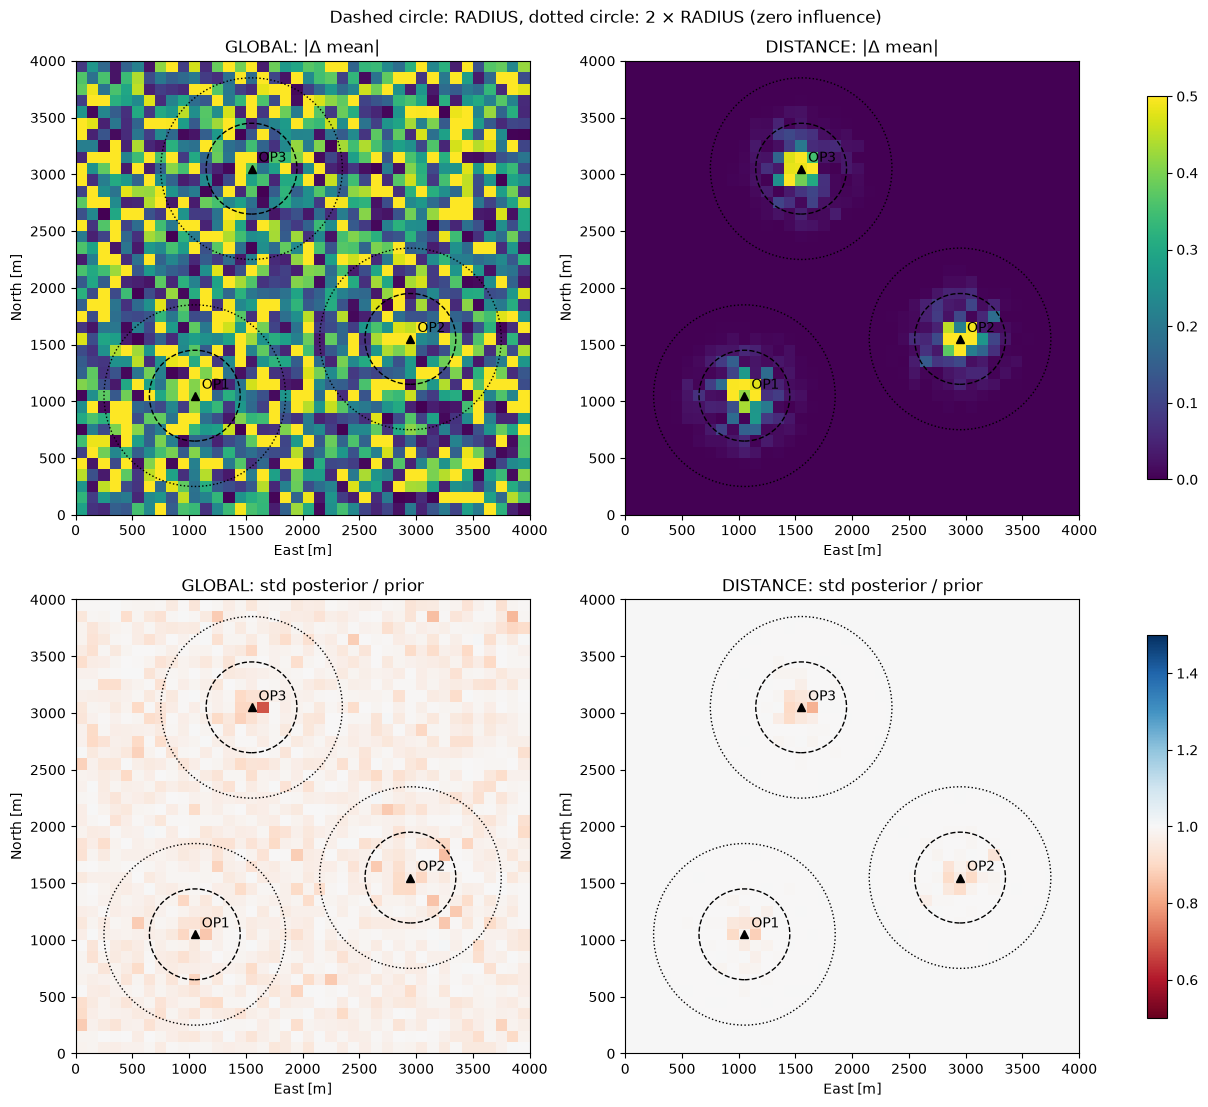

In [7]:
extent = (0, NX * CELL_SIZE, 0, NY * CELL_SIZE)


def show(ax, image, title, cmap, vmin, vmax):
    im = ax.imshow(image.T, origin="lower", extent=extent, cmap=cmap, vmin=vmin, vmax=vmax)
    for well, (east, north, _) in WELLS.items():
        ax.plot(east, north, "k^")
        ax.annotate(well, (east, north), xytext=(5, 5), textcoords="offset points")
        ax.add_patch(plt.Circle((east, north), RADIUS, fill=False, ls="--"))
        ax.add_patch(plt.Circle((east, north), 2 * RADIUS, fill=False, ls=":"))
    ax.set_title(title)
    ax.set_xlabel("East [m]")
    ax.set_ylabel("North [m]")
    return im


fig, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for column, (name, posterior) in enumerate(
    [("GLOBAL", posterior_global), ("DISTANCE", posterior_distance)]
):
    mean_change = np.abs(posterior.mean(axis=0) - prior.mean(axis=0))
    std_ratio = posterior.std(axis=0) / prior.std(axis=0)
    im_mean = show(axes[0, column], mean_change, f"{name}: |Δ mean|", "viridis", 0, 0.5)
    im_std = show(axes[1, column], std_ratio, f"{name}: std posterior / prior", "RdBu", 0.5, 1.5)

fig.colorbar(im_mean, ax=axes[0, :], shrink=0.8)
fig.colorbar(im_std, ax=axes[1, :], shrink=0.8)
_ = fig.suptitle("Dashed circle: RADIUS, dotted circle: 2 × RADIUS (zero influence)")

In [8]:
for name, posterior in [("GLOBAL", posterior_global), ("DISTANCE", posterior_distance)]:
    changed = np.abs(posterior - prior).max(axis=0) > 1e-6
    print(f"{name:>8}: {changed.sum():4d} of {NX * NY} cells updated")

  GLOBAL: 1600 of 1600 cells updated
DISTANCE:  555 of 1600 cells updated


## Summary

To use distance based localization in ERT you need two things:

1. A `LOCALIZATION` block (`EAST`, `NORTH` and optionally `RADIUS`) on the
   observations that should be localized.
2. The `DISTANCE` update strategy for the spatial parameter types:

```
ANALYSIS_SET_VAR PARAMETERS FIELD DISTANCE
ANALYSIS_SET_VAR PARAMETERS SURFACE DISTANCE
```

Observations without location data are ignored by the distance based update
(but still used for `GEN_KW` with `GLOBAL`/`ADAPTIVE`).
See the *Distance based localization* how-to and the `LOCALIZATION` keyword
reference for details.